In [73]:
from datetime import datetime
import requests
import pandas as pd
import numpy as np
import time
# --- HÀM TẢI DỮ LIỆU TỪ BINANCE ---
def str_to_millis(date_str):
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol, interval, start_str, end_str):
    base_url = "https://api.binance.us/"
    api_url = "api/v3/klines"
    general_url = base_url + api_url

    start_time = str_to_millis(start_str)
    end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
    end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    while start_time < end_time:
        params = {
            "symbol": symbol.upper(),
            "interval": interval,
            "startTime": start_time,
            "endTime": end_time,
            "limit": 1000
        }
        response = requests.get(general_url, params=params)
        if response.status_code != 200:
            print("Error:", response.status_code, response.text)
            break

        data = response.json()
        if not data:
            break
        all_klines.extend(data)

        last_ts = data[-1][0]
        start_time = last_ts + 1
        time.sleep(0.3)

    df = pd.DataFrame(all_klines, columns=[
        "timestamp", "open", "high", "low", "close", "volume",
        "close_time", "quote_asset_volume", "num_trades",
        "taker_buy_base_volume", "taker_buy_quote_volume", "ignore"
    ])
    df = df[["timestamp", "open", "close", "high", "low", "volume"]]
    df.columns = ["timestamp", "open", "close", "high", "low", "volume"]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df[["open", "close", "high", "low", "volume"]] = df[["open", "close", "high", "low", "volume"]].astype(float)
    df["date"] = df["timestamp"].dt.date
    return df


In [74]:
# --- NHẬP THỜI GIAN ---
symbol = "BTCUSDT"
interval = "15m"
start_date = "01/01/2025"
end_date = "30/06/2025"

print("\U0001F4E5 Đang tải dữ liệu từ Binance...")
original_df_all = fetch_binance_kline_df(symbol, interval, start_date, end_date)
print(f"✅ Dữ liệu đã tải: {len(original_df_all)} dòng, từ {original_df_all['date'].min()} đến {original_df_all['date'].max()}")

# --- TÁCH DỮ LIỆU ---
original_daily_data = dict(tuple(original_df_all.groupby('date')))
original_sorted_dates = sorted(original_daily_data.keys())
if len(original_sorted_dates) < 30:
    raise Exception("❌ Cần ít nhất 30 ngày dữ liệu!")

📥 Đang tải dữ liệu từ Binance...
✅ Dữ liệu đã tải: 17376 dòng, từ 2025-01-01 đến 2025-06-30


In [75]:

original_df_all

,timestamp,open,close,high,low,volume,date
0,2025-01-01 00:00:00,93500.00,93500.00,93500.00,93421.15,0.04659,2025-01-01
1,2025-01-01 00:15:00,93500.00,93700.00,93778.40,93499.99,2.47072,2025-01-01
2,2025-01-01 00:30:00,93600.00,93809.31,93809.31,93600.00,0.63185,2025-01-01
3,2025-01-01 00:45:00,93830.46,94361.03,94361.03,93809.43,0.08308,2025-01-01
4,2025-01-01 01:00:00,94171.90,93923.84,94171.90,93752.93,0.32008,2025-01-01
...,...,...,...,...,...,...,...
17371,2025-06-30 22:45:00,107301.79,107056.17,107301.79,107056.17,0.01968,2025-06-30
17372,2025-06-30 23:00:00,107112.97,107241.32,107241.98,107068.15,0.03017,2025-06-30
17373,2025-06-30 23:15:00,107240.44,107064.34,107240.44,107064.34,0.01951,2025-06-30
17374,2025-06-30 23:30:00,107078.20,107144.71,107144.71,107026.24,0.04333,2025-06-30


In [89]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def calculate_rma(series, period):
    """Calculate Running Moving Average (RMA)"""
    alpha = 1.0 / period
    rma = series.copy()
    for i in range(1, len(series)):
        rma.iloc[i] = alpha * series.iloc[i] + (1 - alpha) * rma.iloc[i-1]
    return rma

def calculate_atr(high, low, close, period=14):
    """Calculate Average True Range (ATR)"""
    tr1 = high - low
    tr2 = abs(high - close.shift(1))
    tr3 = abs(low - close.shift(1))
    tr = pd.concat([tr1, tr2, tr3], axis=1).max(axis=1)
    return tr.rolling(period).mean()

def calculate_adx(high, low, close, period=14):
    """Calculate Average Directional Index (ADX)"""
    # Calculate True Range
    tr = calculate_atr(high, low, close, period)

    # Calculate Directional Movement
    up_move = high.diff()
    down_move = -low.diff()

    plus_dm = pd.Series(0.0, index=high.index)
    minus_dm = pd.Series(0.0, index=high.index)

    # Apply conditions for directional movement
    plus_dm[(up_move > down_move) & (up_move > 0)] = up_move[(up_move > down_move) & (up_move > 0)]
    minus_dm[(down_move > up_move) & (down_move > 0)] = down_move[(down_move > up_move) & (down_move > 0)]

    # Smooth DM and TR
    plus_dm_smooth = calculate_rma(plus_dm, period)
    minus_dm_smooth = calculate_rma(minus_dm, period)

    # Calculate DI, handle division by zero
    tr_safe = tr.where(tr > 0, 0.01 * tr.mean() if tr.mean() > 0 else 0.01)  # Use small fraction of mean TR
    plus_di = 100 * plus_dm_smooth / tr_safe
    minus_di = 100 * minus_dm_smooth / tr_safe

    # Calculate DX, handle division by zero
    di_sum = plus_di + minus_di
    di_diff = abs(plus_di - minus_di)
    dx = 100 * di_diff / di_sum.where(di_sum > 0, 0.01 * di_sum.mean() if di_sum.mean() > 0 else 0.01)

    # Calculate ADX
    adx = calculate_rma(dx, period)

    # Fill NaNs only for initial periods where calculations are incomplete
    adx = adx.fillna(method='bfill')

    # Debug: Check for zero or invalid values
    if adx.eq(0).all():
        print("Warning: ADX is all zeros. Checking intermediate calculations:")
        print(f"TR mean: {tr.mean():.4f}, Plus DM mean: {plus_dm.mean():.4f}, Minus DM mean: {minus_dm.mean():.4f}")
        print(f"Plus DI mean: {plus_di.mean():.4f}, Minus DI mean: {minus_di.mean():.4f}, DX mean: {dx.mean():.4f}")

    return adx


def backtest_strategy(df, n_period=96, rma_period=960, adx_threshold=12,
                     atr_initial_sl=1.0, atr_trailing_trigger=3.0,
                     atr_trailing_sl=9.0, atr_pullback_long=13.0, atr_pullback_short=4.0,
                     fee_rate=0.001):
    """
    Backtest a breakout trading strategy with trend and ADX filtering, calculating returns based on position (1, -1, 0) and fees.

    Parameters:
    df: pandas DataFrame with OHLCV data and timestamp column
    n_period: Lookback period for high/low breakout
    rma_period: Period for RMA trend calculation
    adx_threshold: Minimum ADX value for trade entry
    atr_initial_sl: ATR multiplier for initial stop loss
    atr_trailing_trigger: ATR multiplier to trigger trailing stop
    atr_trailing_sl: ATR multiplier for trailing stop
    atr_pullback_long: ATR multiplier for long position profit-taking
    atr_pullback_short: ATR multiplier for short position profit-taking
    fee_rate: Fee percentage per trade (e.g., 0.001 = 0.1%)

    Returns:
    trades: DataFrame containing trade results
    metrics: Dictionary with performance metrics
    """
    df = df.copy()  # Avoid modifying the input DataFrame
    df['timestamp2'] = df['timestamp']
    df.set_index('timestamp2', inplace=True)

    # Validate input
    if not all(col in df.columns for col in ['open', 'high', 'low', 'close', 'volume']):
        raise ValueError("DataFrame must contain OHLCV columns")

    # Calculate indicators
    df['high_n'] = df['high'].rolling(n_period).max()
    df['low_n'] = df['low'].rolling(n_period).min()
    df['rma'] = calculate_rma(df['close'], rma_period)
    df['adx'] = calculate_adx(df['high'], df['low'], df['close'], period=14)
    df['atr'] = calculate_atr(df['high'], df['low'], df['close'], period=14)

    # Debug: Print first 20 rows of indicators
    # print(df[['close', 'high_n', 'low_n', 'rma', 'adx', 'atr']].head(20))

    # Calculate ADX ascending
    df['adx_diff'] = df['adx'].diff()
    df['adx_ascending'] = df['adx_diff'] > 0

    # Initialize variables
    trades = []
    position = 0  # 1 for long, -1 for short, 0 for no position
    entry_price = 0
    stop_loss = 0
    highest_price = 0
    lowest_price = float('inf')
    trailing_active = False
    long_signal_count = 0
    short_signal_count = 0
    market_returns = df['close'].pct_change().fillna(0)
    strategy_returns = [0] * len(df)  # Per-period returns
    fees = [0] * len(df)  # Per-period fees

    for i in range(1, len(df)):
        # Calculate strategy return based on previous period's position
        strategy_returns[i] = market_returns.iloc[i] * position

        # Check for breakout signals
        long_signal = (df['close'].iloc[i] > df['high_n'].iloc[i-1] and
                      df['close'].iloc[i] > df['rma'].iloc[i] and
                      df['adx'].iloc[i] > adx_threshold and
                      df['adx_ascending'].iloc[i])

        short_signal = (df['close'].iloc[i] < df['low_n'].iloc[i-1] and
                       df['close'].iloc[i] < df['rma'].iloc[i] and
                       df['adx'].iloc[i] > adx_threshold and
                       df['adx_ascending'].iloc[i])

        # Entry logic
        if position == 0:
            if long_signal:
                long_signal_count += 1
                position = 1
                entry_price = df['close'].iloc[i]
                stop_loss = entry_price - (df['atr'].iloc[i] * atr_initial_sl)
                highest_price = entry_price
                trailing_active = False
                entry_time = df.index[i]
                # Apply entry fee
                fees[i] = fee_rate
                strategy_returns[i] -= fee_rate

            elif short_signal:
                short_signal_count += 1
                position = -1
                entry_price = df['close'].iloc[i]
                stop_loss = entry_price + (df['atr'].iloc[i] * atr_initial_sl)
                lowest_price = entry_price
                trailing_active = False
                entry_time = df.index[i]
                # Apply entry fee
                fees[i] = fee_rate
                strategy_returns[i] -= fee_rate

        # Position management
        elif position == 1:  # Long
            # Update highest price
            highest_price = max(highest_price, df['close'].iloc[i])

            # Check trailing stop trigger
            if not trailing_active and (df['close'].iloc[i] - entry_price) >= (df['atr'].iloc[i] * atr_trailing_trigger):
                trailing_active = True

            # Update stop loss if trailing
            if trailing_active:
                new_stop = highest_price - (df['atr'].iloc[i] * atr_trailing_sl)
                stop_loss = max(stop_loss, new_stop)

            # Check for exit conditions
            pullback = highest_price - df['close'].iloc[i]
            if (df['close'].iloc[i] <= stop_loss or
                (trailing_active and pullback >= (df['atr'].iloc[i] * atr_pullback_long))):
                exit_price = df['close'].iloc[i]
                # Apply exit fee
                fees[i] = fee_rate
                strategy_returns[i] -= fee_rate
                trades.append({
                    'entry_time': entry_time,
                    'exit_time': df.index[i],
                    'position': 'long',
                    'entry_price': entry_price,
                    'exit_price': exit_price,
                    'profit': exit_price - entry_price,
                    'entry_fee': fee_rate * entry_price,
                    'exit_fee': fee_rate * exit_price,
                    'net_profit': (exit_price - entry_price) - (fee_rate * (entry_price + exit_price))
                })
                position = 0

        elif position == -1:  # Short
            # Update lowest price
            lowest_price = min(lowest_price, df['close'].iloc[i])

            # Check trailing stop trigger
            if not trailing_active and (entry_price - df['close'].iloc[i]) >= (df['atr'].iloc[i] * atr_trailing_trigger):
                trailing_active = True

            # Update stop loss if trailing
            if trailing_active:
                new_stop = lowest_price + (df['atr'].iloc[i] * atr_trailing_sl)
                stop_loss = min(stop_loss, new_stop)

            # Check for exit conditions
            pullback = df['close'].iloc[i] - lowest_price
            if (df['close'].iloc[i] >= stop_loss or
                (trailing_active and pullback >= (df['atr'].iloc[i] * atr_pullback_short))):
                exit_price = df['close'].iloc[i]
                # Apply exit fee
                fees[i] = fee_rate
                strategy_returns[i] -= fee_rate
                trades.append({
                    'entry_time': entry_time,
                    'exit_time': df.index[i],
                    'position': 'short',
                    'entry_price': entry_price,
                    'exit_price': exit_price,
                    'profit': entry_price - exit_price,
                    'entry_fee': fee_rate * entry_price,
                    'exit_fee': fee_rate * exit_price,
                    'net_profit': (entry_price - exit_price) - (fee_rate * (entry_price + exit_price))
                })
                position = 0

    # Convert trades to DataFrame
    trades_df = pd.DataFrame(trades)

    # Calculate cumulative returns
    strategy_cumulative = (1 + np.array(strategy_returns)).cumprod() - 1
    market_cumulative = (1 + market_returns).cumprod() - 1

    # Calculate total returns
    strategy_return = strategy_cumulative[-1] if len(strategy_cumulative) > 0 else 0.0
    market_return = market_cumulative[-1] if len(market_cumulative) > 0 else 0.0

    # Calculate performance metrics
    if not trades_df.empty:
        trades_df['return'] = trades_df['net_profit'] / trades_df['entry_price']
        trades_df['holding_period'] = (trades_df['exit_time'] - trades_df['entry_time']).dt.total_seconds() / 3600

        metrics = {
            'total_trades': len(trades_df),
            'win_rate': len(trades_df[trades_df['net_profit'] > 0]) / len(trades_df),
            'avg_return': trades_df['return'].mean() if not trades_df['return'].empty else 0,
            'total_net_profit': trades_df['net_profit'].sum(),
            'avg_holding_period_hours': trades_df['holding_period'].mean(),
            'total_fees': sum(fees),
            'market_return': market_return,
            'strategy_return': strategy_return
        }
    else:
        metrics = {
            'total_trades': 0,
            'win_rate': 0,
            'avg_return': 0,
            'total_net_profit': 0,
            'avg_holding_period_hours': 0,
            'total_fees': sum(fees),
            'market_return': market_return,
            'strategy_return': strategy_return
        }

    # Plot equity curve
    plt.figure(figsize=(10, 6))
    plt.plot(df.index, strategy_cumulative, label='Strategy Return', color='blue')
    plt.plot(df.index, market_cumulative, label='Market Return (Buy & Hold)', color='green', linestyle='--')
    plt.title('Cumulative Returns: Strategy vs. Market')
    plt.xlabel('Date')
    plt.ylabel('Cumulative Return')
    plt.legend()
    plt.grid(True)

    plt.show()

    print(f"Long signals: {long_signal_count}, Short signals: {short_signal_count}")
    return trades_df, metrics

/tmp/ipython-input-883483844.py:55: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  adx = adx.fillna(method='bfill')
/tmp/ipython-input-883483844.py:244: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  market_return = market_cumulative[-1] if len(market_cumulative) > 0 else 0.0


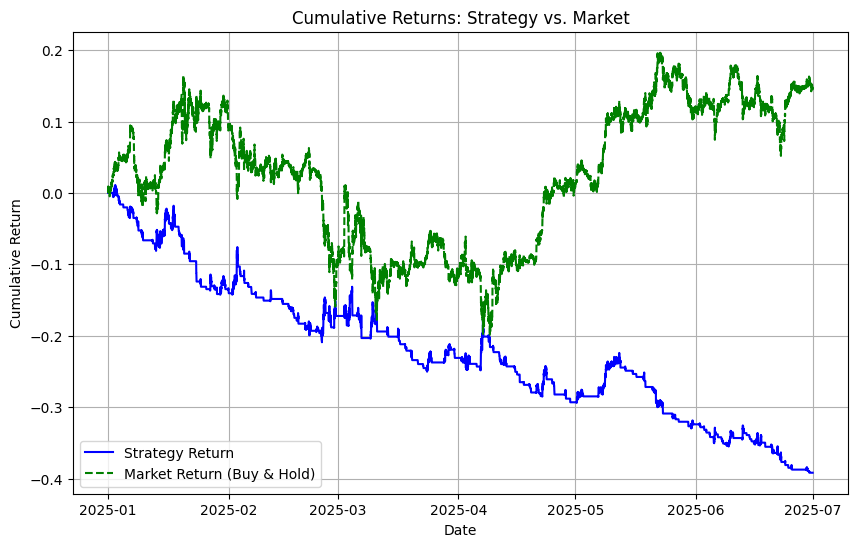

Long signals: 96, Short signals: 76


(             entry_time           exit_time position  entry_price  exit_price  \
 0   2025-01-02 04:30:00 2025-01-02 05:45:00     long     95819.65    95549.79   
 1   2025-01-02 08:45:00 2025-01-03 08:15:00     long     96077.94    96306.01   
 2   2025-01-03 16:15:00 2025-01-03 16:45:00     long     98125.71    97755.81   
 3   2025-01-03 18:15:00 2025-01-04 00:00:00     long     98443.25    98052.34   
 4   2025-01-04 21:00:00 2025-01-04 21:30:00     long     98692.98    98477.10   
 ..                  ...                 ...      ...          ...         ...   
 167 2025-06-23 22:00:00 2025-06-23 22:30:00     long    105369.31   104853.33   
 168 2025-06-24 16:45:00 2025-06-24 17:15:00     long    106120.23   105677.91   
 169 2025-06-25 11:45:00 2025-06-25 15:30:00     long    107213.60   106981.27   
 170 2025-06-29 08:30:00 2025-06-29 16:15:00     long    107671.99   107563.46   
 171 2025-06-30 00:15:00 2025-06-30 03:15:00     long    108663.15   108433.48   
 
      profit  

In [90]:
backtest_strategy(original_df_all)